<a href="https://colab.research.google.com/github/syifahumaira17/simuteh-2330511079/blob/main/B2_citra_warna.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
%cd /content
!git clone https://github.com/syifahumaira17/simuteh-2330511079.git

/content
Cloning into 'simuteh-2330511079'...
remote: Enumerating objects: 241, done.
remote: Counting objects: 100% (3/3), done.
remote: Compressing objects: 100% (3/3), done.
remote: Total 241 (delta 0), reused 0 (delta 0), pack-reused 238 (from 1)
Receiving objects: 100% (241/241), 54.35 MiB | 66.74 MiB/s, done.
Resolving deltas: 100% (11/11), done.


In [3]:
%cd /content/simuteh-2330511079
!ls

/content/simuteh-2330511079
B1_lingkungan_Syifa_Humaira.ipynb  data  hasil	requirements.txt  src


In [4]:
%cd /content/simuteh-2330511079

!pip install -q opencv-python-headless numpy matplotlib scikit-image pandas

import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from src.utils_cv import baca, tampil, kontras_bercak

print("Persiapan berhasil!")
print("OpenCV:", cv2.__version__)

/content/simuteh-2330511079
Persiapan berhasil!
OpenCV: 5.0.0


In [5]:
nama = "teh_041.png"

img = baca(f"data/sintetis/citra/{nama}")
md = cv2.imread(f"data/sintetis/mask_daun/{nama}", 0)
mb = cv2.imread(f"data/sintetis/mask_bercak/{nama}", 0)

print("Ukuran citra:", img.shape)
print("Mask daun:", md.shape)
print("Mask bercak:", mb.shape)

Ukuran citra: (480, 640, 3)
Mask daun: (480, 640)
Mask bercak: (480, 640)


KB kanal B   : 1.29
KB kanal G   : 0.07
KB kanal R   : 11.52
KB kanal Gray: 3.84
KB kanal H   : 10.41
KB kanal S   : 0.18
KB kanal V   : 2.27


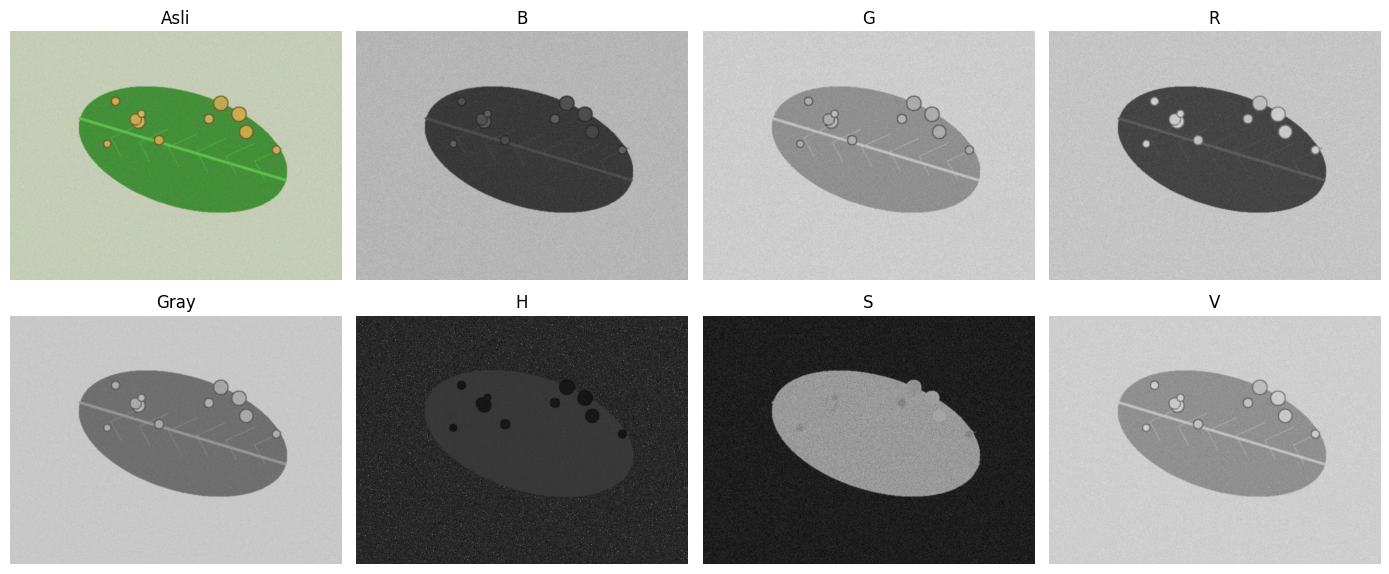

In [6]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

b, g, r = cv2.split(img)
h, s, v = cv2.split(hsv)

kanal = {
    "B": b,
    "G": g,
    "R": r,
    "Gray": gray,
    "H": h,
    "S": s,
    "V": v
}

tampil(
    [img] + list(kanal.values()),
    ["Asli"] + list(kanal.keys()),
    baris=2,
    ukuran=(14, 6)
)

for nm, c in kanal.items():
    print(f"KB kanal {nm:4s}: {kontras_bercak(c, md, mb):.2f}")

In [7]:
# Eksperimen sampling
print("HASIL SAMPLING")

for fx in [0.5, 0.2, 0.1, 0.05]:
    kecil = cv2.resize(
        gray, None, fx=fx, fy=fx,
        interpolation=cv2.INTER_AREA
    )

    besar = cv2.resize(
        kecil, gray.shape[::-1],
        interpolation=cv2.INTER_NEAREST
    )

    kb = kontras_bercak(besar, md, mb)

    print(f"fx={fx}: ukuran={kecil.shape}, KB={kb:.2f}")


# Eksperimen kuantisasi
print("\nHASIL KUANTISASI")

for k in [1, 2, 3, 4, 8]:
    langkah = 256 // (2 ** k)
    kuant = (gray // langkah) * langkah

    kb = kontras_bercak(kuant, md, mb)

    print(
        f"k={k}: {len(np.unique(kuant))} level, "
        f"KB={kb:.2f}"
    )

HASIL SAMPLING
fx=0.5: ukuran=(240, 320), KB=4.15
fx=0.2: ukuran=(96, 128), KB=3.67
fx=0.1: ukuran=(48, 64), KB=2.53
fx=0.05: ukuran=(24, 32), KB=1.08

HASIL KUANTISASI
k=1: 2 level, KB=2.94
k=2: 3 level, KB=2.94
k=3: 5 level, KB=4.79
k=4: 10 level, KB=2.96
k=8: 146 level, KB=3.84


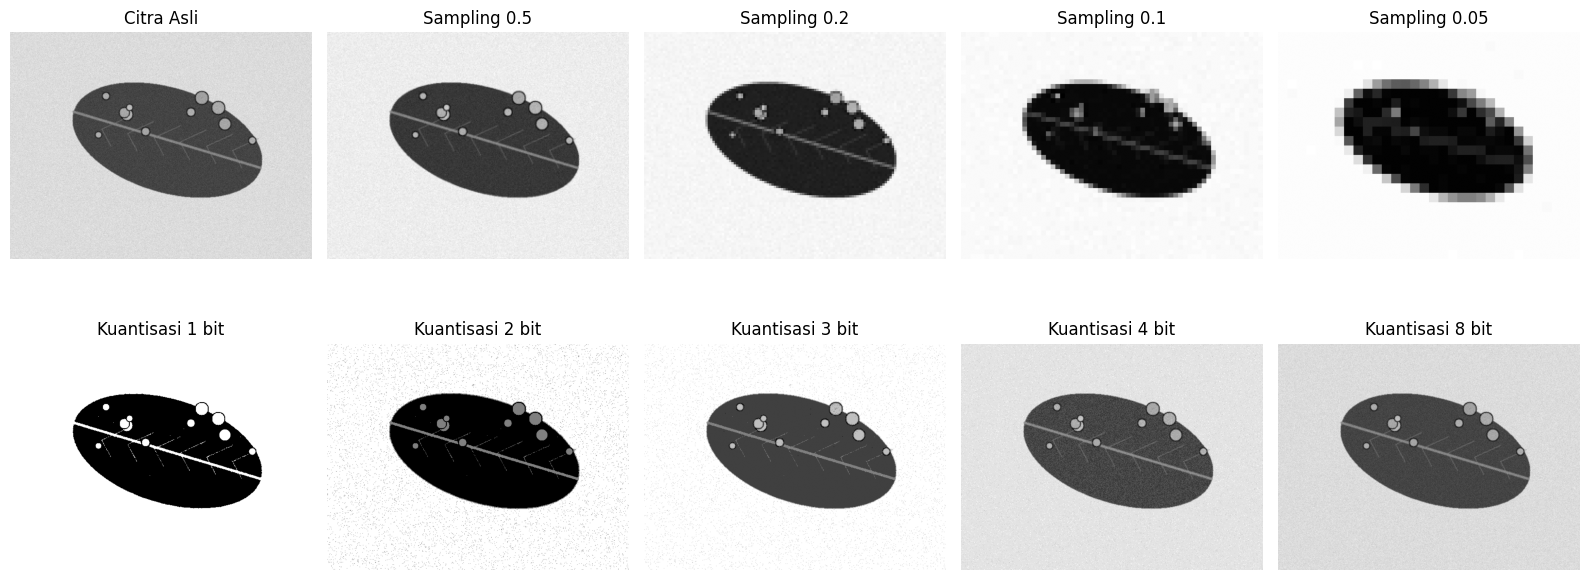

In [8]:
fig, axes = plt.subplots(2, 5, figsize=(16, 7))

# Citra asli
axes[0, 0].imshow(gray, cmap="gray")
axes[0, 0].set_title("Citra Asli")

# Hasil sampling
for i, fx in enumerate([0.5, 0.2, 0.1, 0.05], start=1):
    kecil = cv2.resize(
        gray, None, fx=fx, fy=fx,
        interpolation=cv2.INTER_AREA
    )
    besar = cv2.resize(
        kecil, gray.shape[::-1],
        interpolation=cv2.INTER_NEAREST
    )

    axes[0, i].imshow(besar, cmap="gray")
    axes[0, i].set_title(f"Sampling {fx}")

# Hasil kuantisasi
for i, k in enumerate([1, 2, 3, 4, 8]):
    langkah = 256 // (2 ** k)
    kuant = (gray // langkah) * langkah

    axes[1, i].imshow(kuant, cmap="gray")
    axes[1, i].set_title(f"Kuantisasi {k} bit")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.savefig("hasil/b2_sampling_kuantisasi.png")
plt.show()

In [9]:
def semua_kanal(img):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    b, g, r = cv2.split(img)
    h, s, v = cv2.split(hsv)

    return {
        "B": b,
        "G": g,
        "R": r,
        "Gray": cv2.cvtColor(img, cv2.COLOR_BGR2GRAY),
        "H": h,
        "S": s,
        "V": v
    }


label = pd.read_csv("data/sintetis/label.csv")

baris = []

for _, d in label[label.kelas == "berat"].iterrows():
    im = baca(f"data/sintetis/citra/{d.nama_file}")

    m_d = cv2.imread(
        f"data/sintetis/mask_daun/{d.nama_file}", 0
    )

    m_b = cv2.imread(
        f"data/sintetis/mask_bercak/{d.nama_file}", 0
    )

    kb = {
        k: kontras_bercak(c, m_d, m_b)
        for k, c in semua_kanal(im).items()
    }

    kb["kondisi"] = d.kondisi_cahaya
    baris.append(kb)

tabel_kb = (
    pd.DataFrame(baris)
    .groupby("kondisi")
    .mean()
    .round(2)
)

print(tabel_kb)

tabel_kb.to_csv("hasil/b2_kb_kanal.csv")
print("\nFile berhasil disimpan!")

                   B     G      R  Gray     H     S     V
kondisi                                                  
bayangan        1.36  0.34   5.16  1.67  4.25  0.92  0.99
gelap           1.23  0.50   8.62  3.32  5.77  1.02  2.03
kontras_rendah  0.77  0.39   3.98  2.18  2.11  0.21  1.36
normal          1.86  0.59  10.87  4.52  8.89  1.04  2.36
terang          1.77  0.74   6.16  3.46  4.46  0.70  1.80

File berhasil disimpan!


RATA-RATA KB KELAS RINGAN
                   B     G     R  Gray     H     S     V
kondisi                                                 
bayangan        1.03  0.49  5.28  1.37  5.70  0.88  0.75
gelap           1.07  0.48  8.75  3.14  6.15  0.93  2.01
kontras_rendah  0.73  0.17  3.01  1.45  1.28  0.27  0.91
normal          1.10  0.97  8.00  2.29  7.93  1.29  0.73
terang          1.76  0.56  6.69  2.99  6.03  1.20  1.22

teh_021.png
Nilai KB setiap kanal: {'B': np.float64(1.9589323932285438), 'G': np.float64(0.004463965929241747), 'R': np.float64(6.709818911761536), 'Gray': np.float64(2.77419862559259), 'H': np.float64(5.91894786804366), 'S': np.float64(1.248354148074612), 'V': np.float64(1.533359752322455)}
Kanal terbaik: R
Nilai KB tertinggi: 6.71


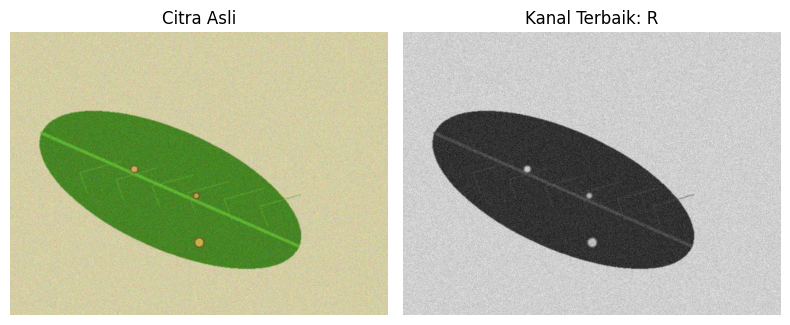


teh_045.png
Nilai KB setiap kanal: {'B': np.float64(1.0998616297789914), 'G': np.float64(0.3835069950898397), 'R': np.float64(5.5209937631489), 'Gray': np.float64(1.7600156598285062), 'H': np.float64(4.062565462616398), 'S': np.float64(0.8451083751424492), 'V': np.float64(1.049821109673426)}
Kanal terbaik: R
Nilai KB tertinggi: 5.52


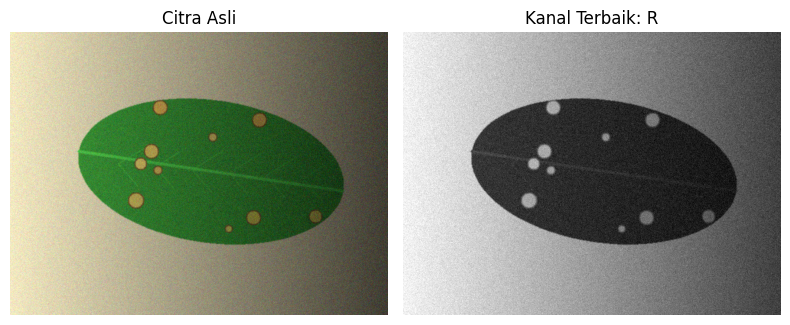


Pengujian kelas ringan selesai!


In [10]:
# Menghitung KB untuk 20 citra kelas ringan
baris_ringan = []

for _, d in label[label.kelas == "ringan"].iterrows():
    im = baca(f"data/sintetis/citra/{d.nama_file}")

    m_d = cv2.imread(
        f"data/sintetis/mask_daun/{d.nama_file}", 0
    )

    m_b = cv2.imread(
        f"data/sintetis/mask_bercak/{d.nama_file}", 0
    )

    kb = {
        k: kontras_bercak(c, m_d, m_b)
        for k, c in semua_kanal(im).items()
    }

    kb["kondisi"] = d.kondisi_cahaya
    baris_ringan.append(kb)

tabel_ringan = (
    pd.DataFrame(baris_ringan)
    .groupby("kondisi")
    .mean()
    .round(2)
)

print("RATA-RATA KB KELAS RINGAN")
print(tabel_ringan)

tabel_ringan.to_csv("hasil/b2_kb_kanal_ringan.csv")


# Menampilkan kanal terbaik untuk teh_021 dan teh_045
for nama in ["teh_021.png", "teh_045.png"]:
    im = baca(f"data/sintetis/citra/{nama}")

    m_d = cv2.imread(
        f"data/sintetis/mask_daun/{nama}", 0
    )

    m_b = cv2.imread(
        f"data/sintetis/mask_bercak/{nama}", 0
    )

    kanal = semua_kanal(im)

    hasil_kb = {
        k: kontras_bercak(c, m_d, m_b)
        for k, c in kanal.items()
    }

    terbaik = max(hasil_kb, key=hasil_kb.get)

    print(f"\n{nama}")
    print("Nilai KB setiap kanal:", hasil_kb)
    print("Kanal terbaik:", terbaik)
    print("Nilai KB tertinggi:", round(hasil_kb[terbaik], 2))

    plt.figure(figsize=(8, 4))

    plt.subplot(1, 2, 1)
    plt.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
    plt.title("Citra Asli")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(kanal[terbaik], cmap="gray")
    plt.title(f"Kanal Terbaik: {terbaik}")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

print("\nPengujian kelas ringan selesai!")